# Customer Shopping Behaviour Analysis
### Python · PostgreSQL · Tableau

**Business question:** a retailer wants to know which customers, products and programmes (subscriptions, discounts) drive revenue, so it can decide where to focus marketing and loyalty spend.

**Data:** 3,900 customers, one purchase each, with demographics, product, amount (USD), review rating, subscription and discount flags, shipping, payment method, previous purchase count and stated purchase frequency. There are no dates or order IDs.

**Approach:** audit the data → clean it with documented rules (`src/cleaning.py`) → answer the business questions, **testing whether each difference is real** before calling it a finding → load to PostgreSQL for the SQL version (`sql/business_questions.sql`) → export the cleaned table for the Tableau dashboard.

## Executive summary

1. **Revenue differences between customer groups come from how many customers are in each group, not from how much they spend.** Average spend is $57–61 in every gender, age, category, season, shipping, payment and loyalty group, and none of these 12 comparisons is statistically significant after correcting for multiple tests. Men generate 68% of revenue because they are 68% of customers.
2. **The subscription and discount programmes cannot be evaluated from this data.** Every subscriber also received a discount, and no female customer ever subscribed or received a discount. Subscribers spend $59.49 on average versus $59.87 for non-subscribers (p = 0.66).
3. **Subscription rates rise with purchase history:** 18% of New customers, 24% of Returning and 28% of Loyal customers subscribe (chi-square p = 0.023). This is the clearest relationship in the data, but it is modest and does not show which causes which.
4. **Product ratings do not separate products.** The average rating is 3.75 out of 5. The "top-rated" products sit about 0.1 points above average, and ratings do not differ significantly across products (p = 0.66) or categories (p = 0.11).
5. **The data has generation artefacts** (perfectly uniform distributions, identical promo and discount columns, duplicated frequency labels, rows sorted by flags), consistent with a synthetic dataset. Findings describe this dataset, not real shoppers.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT))

from src.cleaning import load_raw, quality_report, clean, write_processed
from src.analysis import compare_spend, compare_rate, spend_test_summary
from src.charts import set_chart_style, mean_ci, proportion_ci, PRIMARY, MUTED, ACCENT, INK

set_chart_style()
pd.set_option("display.float_format", "{:,.2f}".format)
FIGURES = REPO_ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

## 1. Data audit

Every check runs on the raw file before any cleaning. The raw data is never modified.

In [2]:
raw = load_raw()  # data/raw/customer_shopping_behavior.csv, or CUSTOMER_DATA_PATH
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns; Customer ID unique: {raw['Customer ID'].is_unique}")
quality_report(raw)

3,900 rows x 18 columns; Customer ID unique: True


,check,rows
0,Rows,3900
1,Duplicate rows,0
2,Duplicate Customer IDs,0
3,Missing Review Rating,37
4,Missing values in other columns,0
5,Age outside 18-100,0
6,Purchase amount <= 0,0
7,Review rating outside 1-5,0
8,Previous purchases < 1,0
9,Rows where Promo Code Used differs from Discou...,0


**What the audit shows**

- **Structurally clean:** no duplicates, no impossible values, and each `Customer ID` appears once. Each row is therefore one customer *and* one purchase, so "average spend per customer" and "average order value" are the same number here.
- **37 missing review ratings** (1%). They are filled with the median rating of the same category, and a `review_rating_imputed` flag keeps track of them.
- **`Promo Code Used` is identical to `Discount Applied` on all 3,900 rows**, so it adds no information and is dropped.
- **Frequency labels overlap:** "Bi-Weekly" and "Fortnightly" mean the same thing, as do "Every 3 Months" and "Quarterly" (1,131 rows affected). They are merged.
- **The programme flags are entangled:** every subscriber received a discount, and no female customer subscribed or received a discount. Section 3 explains why this matters.

In [3]:
print("Rows are sorted by flags (first/last row index where the flag is 'Yes' or 'Male'):")
for column, value in [("Subscription Status", "Yes"), ("Discount Applied", "Yes"), ("Gender", "Male")]:
    rows = raw.index[raw[column] == value]
    print(f"  {column} = {value}: rows {rows.min()}-{rows.max()} ({len(rows):,} rows, all consecutive: {len(rows) == rows.max() + 1})")

for column in ["Season", "Payment Method", "Shipping Type"]:
    counts = raw[column].value_counts()
    print(f"{column}: smallest group {counts.min()}, largest {counts.max()}")

Rows are sorted by flags (first/last row index where the flag is 'Yes' or 'Male'):
  Subscription Status = Yes: rows 0-1052 (1,053 rows, all consecutive: True)
  Discount Applied = Yes: rows 0-1676 (1,677 rows, all consecutive: True)
  Gender = Male: rows 0-2651 (2,652 rows, all consecutive: True)
Season: smallest group 955, largest 999
Payment Method: smallest group 612, largest 677
Shipping Type: smallest group 627, largest 675


**Evidence the data is synthetic.** All subscribers sit in one block at the top of the file, inside the block of discount users, inside the block of male customers. Categories such as season, payment method and shipping type are almost perfectly balanced, and spend and ratings are unrelated to anything else (shown below). Real transaction data does not look like this. This analysis therefore treats the dataset as a **practice dataset**: the methods are what transfer to real work, and every finding is stated as a property of this data.

## 2. Cleaning

All rules are in `src/cleaning.py` (`clean()`), so the notebook, the PostgreSQL table and the Tableau file are built from identical data.

In [4]:
df = clean(raw)
processed_path = write_processed(df)  # data/processed/customer_clean.csv, used by Tableau
print(f"Cleaned: {df.shape[0]:,} rows x {df.shape[1]} columns -> {processed_path.relative_to(REPO_ROOT)}")
print(f"Revenue check: raw ${raw['Purchase Amount (USD)'].sum():,} = cleaned ${df['purchase_amount'].sum():,}")
df.head(3)

Cleaned: 3,900 rows x 22 columns -> data/processed/customer_clean.csv
Revenue check: raw $233,081 = cleaned $233,081


,customer_id,age,gender,item_purchased,category,purchase_amount,location,size,color,season,...,shipping_type,discount_applied,previous_purchases,payment_method,review_rating_imputed,purchase_frequency,purchase_frequency_days,age_group,customer_segment,is_repeat_buyer
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,...,Express,Yes,14,Venmo,False,Fortnightly,14,Middle-Aged,Loyal,True
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,...,Express,Yes,2,Cash,False,Fortnightly,14,Young-Adult,Returning,False
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,...,Free Shipping,Yes,23,Credit Card,False,Weekly,7,Middle-Aged,Loyal,True


In [5]:
print(df.groupby("age_group", observed=True)["age"].agg(["min", "max", "count"]))
print()
print(df["customer_segment"].value_counts().reindex(["New", "Returning", "Loyal"]))

             min  max  count
age_group                   
Young-Adult   18   31   1028
Adult         32   44    942
Middle-Aged   45   57    986
Senior        58   70    944

customer_segment
New            83
Returning     701
Loyal        3116
Name: count, dtype: int64


| Derived field | Rule | Why |
|---|---|---|
| `review_rating_imputed` | True for the 37 filled ratings | Lets any rating result be checked with and without imputed values |
| `purchase_frequency`, `purchase_frequency_days` | Merged labels; Weekly 7, Fortnightly 14, Monthly 30, Quarterly 90, Annually 365 days | Removes duplicate categories |
| `age_group` | Four equal-sized age bands: 18–31, 32–44, 45–57, 58–70 | Comparable group sizes |
| `customer_segment` | New = 1 previous purchase, Returning = 2–10, Loyal = 11+ | Same thresholds as the SQL (Q7) |
| `is_repeat_buyer` | More than 5 previous purchases | Same definition as the SQL (Q9) |

**Caveat on segments:** previous purchases are spread evenly from 1 to 50, so 80% of customers land in "Loyal". The thresholds come from the original business question, not from the data.

## 3. Findings

### Finding 1: Spend per customer is the same in every group; revenue differences are volume

**Question:** which customer groups are most valuable? **Method:** compare average spend per group with Welch's t-test (2 groups) or ANOVA (3+ groups), correcting for the 12 groupings tested.

In [6]:
groupings = ["gender", "subscription_status", "discount_applied", "category", "season", "age_group",
             "customer_segment", "shipping_type", "payment_method", "size", "purchase_frequency", "location"]
spend_tests = spend_test_summary(df, groupings)
print(f"Overall average spend: ${df['purchase_amount'].mean():.2f}")
print(f"Bonferroni threshold for {len(groupings)} tests: p < {0.05 / len(groupings):.4f}")
spend_tests

Overall average spend: $59.76
Bonferroni threshold for 12 tests: p < 0.0042


,groups,lowest_avg_spend,highest_avg_spend,gap_usd,p_value,significant_at_5pct,significant_after_correction
grouping,,,,,,,
season,4,58.41,61.56,3.15,0.01,True,False
location,50,54.18,67.60,13.42,0.10,False,False
size,4,58.56,61.04,2.47,0.19,False,False
category,4,57.17,60.26,3.08,0.23,False,False
discount_applied,2,59.28,60.13,0.85,0.27,False,False
customer_segment,3,58.47,60.93,2.46,0.33,False,False
shipping_type,6,58.46,60.73,2.27,0.35,False,False
gender,2,59.54,60.25,0.71,0.38,False,False
age_group,4,59.07,60.45,1.38,0.57,False,False


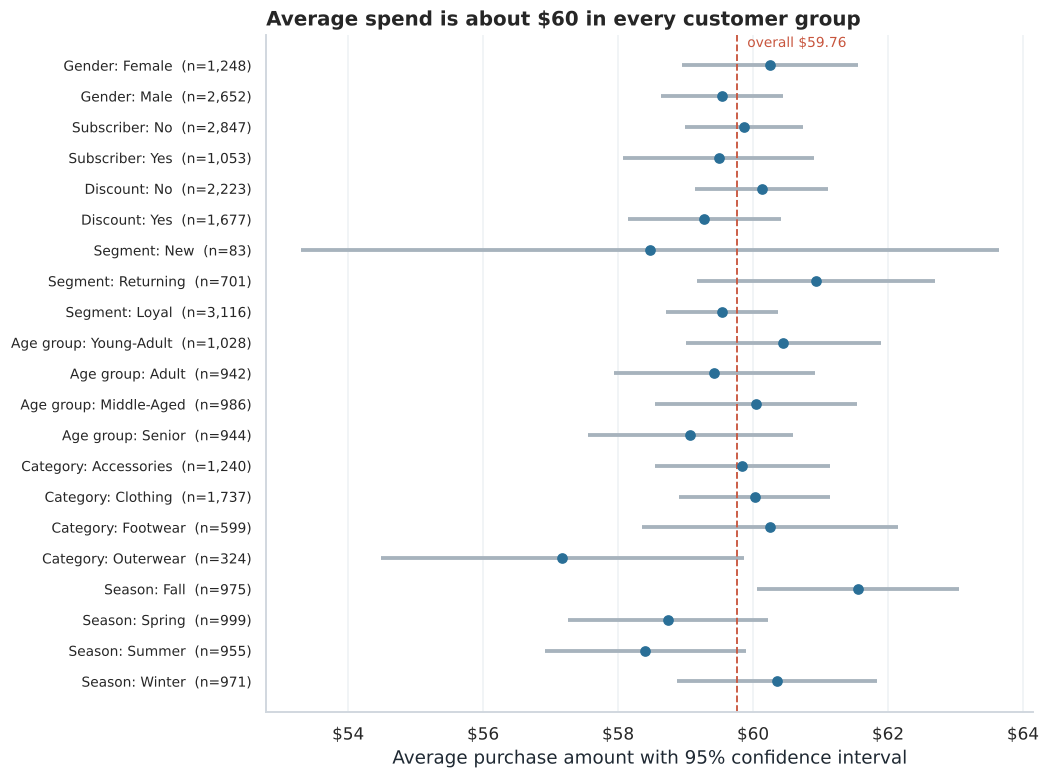

In [7]:
show = ["gender", "subscription_status", "discount_applied", "customer_segment", "age_group", "category", "season"]
labels = {"gender": "Gender", "subscription_status": "Subscriber", "discount_applied": "Discount",
          "customer_segment": "Segment", "age_group": "Age group", "category": "Category", "season": "Season"}
rows = []
for group in show:
    for level, values in df.groupby(group, observed=True)["purchase_amount"]:
        mean, half = mean_ci(values)
        rows.append((f"{labels[group]}: {level}", mean, half, len(values)))
plot_df = pd.DataFrame(rows, columns=["label", "mean", "half", "n"]).iloc[::-1]

overall = df["purchase_amount"].mean()
fig, ax = plt.subplots(figsize=(9, 8))
y = np.arange(len(plot_df))
ax.errorbar(plot_df["mean"], y, xerr=plot_df["half"], fmt="o", color=PRIMARY, ecolor=MUTED, elinewidth=2.5, capsize=0)
ax.axvline(overall, color=ACCENT, linestyle="--", linewidth=1.2)
ax.text(overall + 0.15, len(plot_df) - 0.4, f"overall ${overall:.2f}", color=ACCENT, fontsize=9)
ax.set_yticks(y, [f"{l}  (n={n:,})" for l, n in zip(plot_df["label"], plot_df["n"])], fontsize=9)
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("${x:.0f}"))
ax.set(title="Average spend is about $60 in every customer group",
       xlabel="Average purchase amount with 95% confidence interval", ylabel="")
ax.grid(axis="y", visible=False)
fig.savefig(FIGURES / "01_spend_by_group.png")
plt.show()

In [8]:
gender_table, gender_p = compare_spend(df, "gender")
print(f"Gender: p = {gender_p:.2f}")
gender_table

Gender: p = 0.38


,customers,share_of_customers,revenue,share_of_revenue,avg_spend
gender,,,,,
Male,2652,0.68,157890,0.68,59.54
Female,1248,0.32,75191,0.32,60.25


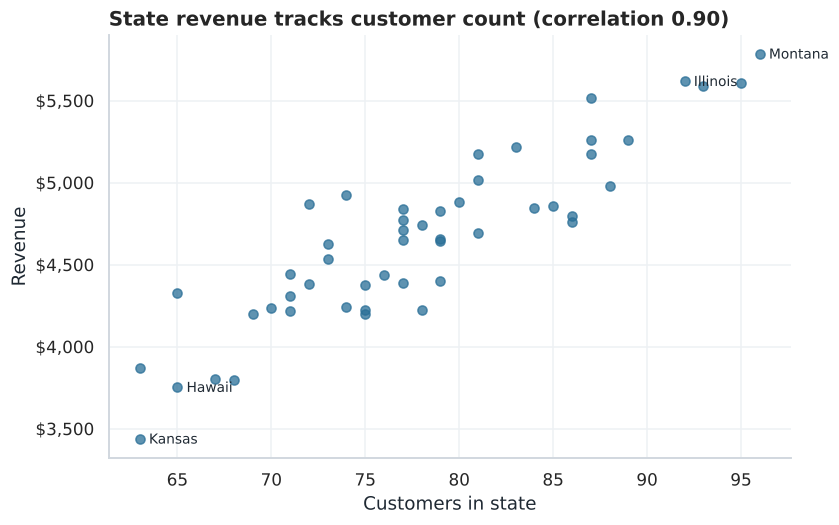

In [9]:
states = df.groupby("location").agg(customers=("customer_id", "size"), revenue=("purchase_amount", "sum"))
r = states["customers"].corr(states["revenue"])

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(states["customers"], states["revenue"], color=PRIMARY, alpha=0.75)
for state in states["revenue"].nlargest(2).index.tolist() + states["revenue"].nsmallest(2).index.tolist():
    ax.annotate(state, (states.loc[state, "customers"], states.loc[state, "revenue"]),
                xytext=(6, -3), textcoords="offset points", fontsize=9, color=INK)
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("${x:,.0f}"))
ax.set(title=f"State revenue tracks customer count (correlation {r:.2f})",
       xlabel="Customers in state", ylabel="Revenue")
fig.savefig(FIGURES / "02_state_revenue_vs_customers.png")
plt.show()

**Result.** Across gender, subscription, discount, category, season, age, segment, shipping, payment, size and frequency groups, average spend ranges only from $57.17 (Outerwear) to $61.56 (Fall), against an overall average of $59.76. Individual states vary more ($54–68) because each has only 60–100 customers, and those differences are also not significant (p = 0.10). Only **season** passes the usual p < 0.05 test (p = 0.011), and nothing passes after correcting for 12 tests (threshold 0.0042). Men account for 67.7% of revenue because they are 68.0% of customers; women actually average slightly more ($60.25 vs $59.54, p = 0.38). Across the 50 states, revenue correlates 0.90 with customer count.

**Interpretation.** In this data, *who* the customer is does not predict *how much* they spend. Revenue rankings by group ("men generate the most revenue", "Montana is the top state") are really customer-count rankings.

**Recommendation.** Report revenue together with customer count and average spend, and set growth targets on acquisition and purchase frequency rather than on targeting a supposedly high-spending demographic.

**Limitation.** One purchase per customer and no dates, so lifetime value and repeat-spend patterns cannot be measured.

### Finding 2: The subscription and discount programmes cannot be evaluated from this data

In [10]:
overlap = (df.groupby(["gender", "subscription_status", "discount_applied"])
             .agg(customers=("customer_id", "size"), avg_spend=("purchase_amount", "mean"))
             .reset_index())
overlap

,gender,subscription_status,discount_applied,customers,avg_spend
0,Female,No,No,1248,60.25
1,Male,No,No,975,59.98
2,Male,No,Yes,624,58.92
3,Male,Yes,Yes,1053,59.49


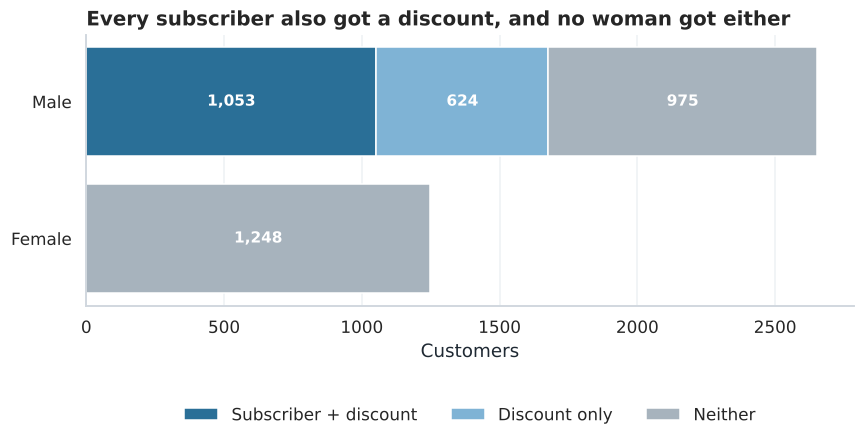

Subscribers vs non-subscribers average spend: p = 0.66


,customers,share_of_customers,revenue,share_of_revenue,avg_spend
subscription_status,,,,,
No,2847,0.73,170436,0.73,59.87
Yes,1053,0.27,62645,0.27,59.49


In [11]:
combo = np.select(
    [df["subscription_status"].eq("Yes"), df["discount_applied"].eq("Yes")],
    ["Subscriber + discount", "Discount only"], default="Neither")
mix = pd.crosstab(df["gender"], combo).reindex(columns=["Subscriber + discount", "Discount only", "Neither"], fill_value=0)

fig, ax = plt.subplots(figsize=(9, 3.2))
left = np.zeros(len(mix))
for column, color in zip(mix.columns, [PRIMARY, "#7fb3d5", MUTED]):
    ax.barh(mix.index, mix[column], left=left, color=color, label=column)
    for i, (value, start) in enumerate(zip(mix[column], left)):
        if value:
            ax.text(start + value / 2, i, f"{value:,}", ha="center", va="center", color="white", fontsize=10, fontweight="bold")
    left += mix[column].to_numpy()
ax.set(title="Every subscriber also got a discount, and no woman got either",
       xlabel="Customers", ylabel="")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=3)
ax.grid(axis="y", visible=False)
fig.savefig(FIGURES / "03_programme_overlap.png")
plt.show()

sub_table, sub_p = compare_spend(df, "subscription_status")
print(f"Subscribers vs non-subscribers average spend: p = {sub_p:.2f}")
sub_table

**Result.** All 1,053 subscribers received a discount; 624 more non-subscribers did too; no female customer did either. Subscribers spend $59.49 on average against $59.87 for everyone else (p = 0.66).

**Interpretation.** Even if subscribers had spent more, the data could not say whether the subscription, the discount or customer gender was responsible, because the three always occur together. "Do subscribers spend more?" has no answer here, and that is the honest finding.

**Recommendation.** Before judging the subscription or discount programmes, capture them independently (for example, record subscriptions without an automatic discount) and test the discount with a randomised experiment: offer it to a random half of eligible customers and compare spend and repeat purchases.

### Finding 3: Customers with more purchase history subscribe more often

In [12]:
df["is_subscriber"] = df["subscription_status"].eq("Yes")
segment_rates, segment_p = compare_rate(df, "customer_segment", "is_subscriber")
repeat_rates, repeat_p = compare_rate(df, "is_repeat_buyer", "is_subscriber")
print(f"By segment: chi-square p = {segment_p:.3f}")
print(segment_rates)
print(f"\nRepeat buyers (>5 previous purchases) vs not: chi-square p = {repeat_p:.3f}")
print(repeat_rates)

By segment: chi-square p = 0.023
                  customers  with_flag  rate
customer_segment                            
New                      83         15  0.18
Returning               701        169  0.24
Loyal                  3116        869  0.28

Repeat buyers (>5 previous purchases) vs not: chi-square p = 0.028
                 customers  with_flag  rate
is_repeat_buyer                            
False                  424         95  0.22
True                  3476        958  0.28


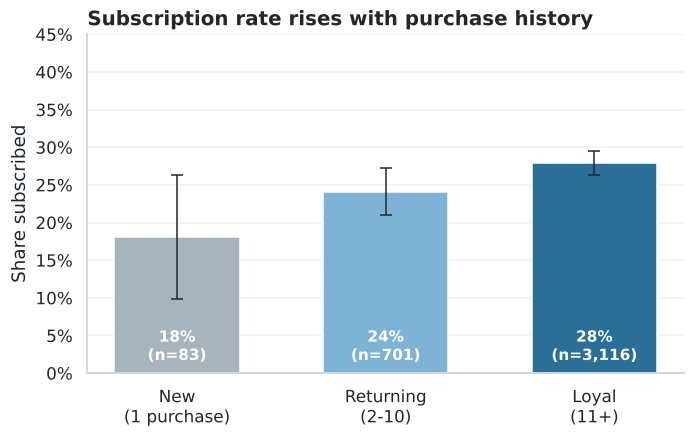

In [13]:
plot_rates = segment_rates.reindex(["New", "Returning", "Loyal"])
cis = [proportion_ci(int(row.with_flag), int(row.customers)) for row in plot_rates.itertuples()]

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(plot_rates))
ax.bar(x, plot_rates["rate"], color=[MUTED, "#7fb3d5", PRIMARY], width=0.6)
ax.errorbar(x, plot_rates["rate"], yerr=[h for _, h in cis], fmt="none", ecolor=INK, capsize=4, linewidth=1)
for xi, (rate, n) in enumerate(zip(plot_rates["rate"], plot_rates["customers"])):
    ax.text(xi + 0.0, 0.035, f"{rate:.0%}\n(n={n:,})", ha="center", va="center", fontsize=10, color="white", fontweight="bold")
ax.set_xticks(x, ["New\n(1 purchase)", "Returning\n(2-10)", "Loyal\n(11+)"])
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
ax.set_ylim(0, 0.45)
ax.set(title="Subscription rate rises with purchase history", ylabel="Share subscribed")
ax.grid(axis="x", visible=False)
fig.savefig(FIGURES / "04_subscription_by_segment.png")
plt.show()

**Result.** 18.1% of New customers, 24.1% of Returning and 27.9% of Loyal customers subscribe (p = 0.023). Customers with more than 5 previous purchases subscribe at 27.6% against 22.4% for the rest (p = 0.028).

**Interpretation.** Purchase history and subscription move together. The direction is unknown: experienced customers may choose to subscribe, or subscribers may buy more often. The New group is small (83 customers), so its rate is uncertain (95% interval roughly 10–26%).

**Recommendation.** Time subscription offers for customers' 2nd–10th purchase, the Returning stage, and test whether doing so raises conversion compared with offering at the first purchase.

### Finding 4: Season shows a small spend difference that may be chance

In [14]:
season_table, season_p = compare_spend(df, "season")
season_table = season_table.reindex(["Spring", "Summer", "Fall", "Winter"])
print(f"Season: ANOVA p = {season_p:.3f} (Bonferroni threshold for 12 tests: {0.05 / 12:.4f})")
season_table

Season: ANOVA p = 0.011 (Bonferroni threshold for 12 tests: 0.0042)


,customers,share_of_customers,revenue,share_of_revenue,avg_spend
season,,,,,
Spring,999,0.26,58679,0.25,58.74
Summer,955,0.24,55777,0.24,58.41
Fall,975,0.25,60018,0.26,61.56
Winter,971,0.25,58607,0.25,60.36


**Result.** Fall has the highest average spend ($61.56) and Summer the lowest ($58.41), a $3.15 gap (p = 0.011). This would be "significant" if it were the only test, but it is one of 12 comparisons, and with that many tests one result below 0.05 is likely by chance alone. After correction it is not significant.

**Recommendation.** Treat it as a hypothesis, not a finding. If seasonal campaigns are planned, check it on a second year of data first.

### Finding 5: Product ratings do not distinguish products

In [15]:
from scipy import stats

item_stats = (df.groupby("item_purchased")["review_rating"]
                .agg(ratings="count", avg_rating="mean")
                .sort_values("avg_rating", ascending=False))
item_p = stats.f_oneway(*[g["review_rating"] for _, g in df.groupby("item_purchased")]).pvalue
category_p = stats.f_oneway(*[g["review_rating"] for _, g in df.groupby("category")]).pvalue
without_imputed = df[~df["review_rating_imputed"]].groupby("item_purchased")["review_rating"].mean()

print(f"Overall average rating: {df['review_rating'].mean():.2f} / 5")
print(f"Ratings differ across products? ANOVA p = {item_p:.2f};  across categories? p = {category_p:.2f}")
print(f"Top 5 unchanged when imputed ratings are excluded: "
      f"{list(item_stats.index[:5]) == list(without_imputed.sort_values(ascending=False).index[:5])}")
pd.concat([item_stats.head(5), item_stats.tail(5)])

Overall average rating: 3.75 / 5
Ratings differ across products? ANOVA p = 0.66;  across categories? p = 0.11
Top 5 unchanged when imputed ratings are excluded: True


,ratings,avg_rating
item_purchased,,
Gloves,140,3.86
Sandals,160,3.84
Boots,144,3.82
Hat,154,3.80
Skirt,158,3.78
Shorts,157,3.71
Scarf,157,3.71
Blouse,171,3.68
Jeans,124,3.65


**Result.** The top-rated product (Gloves, 3.86) is 0.11 points above the 3.75 average; the lowest-rated products are a similar distance below. Differences across products (p = 0.66) and categories (p = 0.11) are consistent with chance.

**Recommendation.** Do not use these average ratings to rank or promote products. In real data, combine ratings with review counts (for example, a vote-weighted rating) and with returns data.

## 4. Recommendations

| # | Recommendation | Based on | Evidence level |
|---|---|---|---|
| 1 | Report revenue with customer count and average spend; focus growth on acquisition and frequency | Finding 1 | Observed in this data |
| 2 | Separate subscription and discount tracking; test discounts with a randomised experiment | Finding 2 | Data limitation, observed |
| 3 | Target subscription offers at Returning customers and test the timing | Finding 3 | Association; causation untested |
| 4 | Do not plan seasonal campaigns on the Fall/Summer gap without more data | Finding 4 | Weak, likely chance |
| 5 | Do not rank products on average rating alone | Finding 5 | Observed in this data |

## 5. Limitations

- **Probably synthetic data** (Section 1), so results describe this dataset only.
- **One purchase per customer, no dates or order IDs:** no trends over time, retention, cohorts or customer lifetime value.
- **No costs or margins:** revenue only, so nothing here is about profit.
- **Imputed ratings:** 37 ratings (1%) are category medians; the product-rating result was checked with and without them.
- **Many comparisons:** results are reported with p-values and a multiple-testing correction to avoid over-reading chance differences.

In [16]:
# Validation: fail loudly if a code or data change breaks an invariant
assert len(df) == len(raw) == df["customer_id"].nunique()
assert df["purchase_amount"].sum() == raw["Purchase Amount (USD)"].sum()
assert not df.drop(columns="is_subscriber").isna().any().any()
assert df["customer_segment"].value_counts().sum() == len(df)
assert set(df["purchase_frequency"]) == {"Weekly", "Fortnightly", "Monthly", "Quarterly", "Annually"}
assert abs(spend_tests["highest_avg_spend"].max() - spend_tests["lowest_avg_spend"].min()) < 15
print("All validation checks passed.")

All validation checks passed.
